# Análise Comparativa de Modelos de PLN para Classificação de Notícias sobre o Conflito Rússia–Ucrânia

**Autor:** David L. B. de Oliveira  
**Orientador:** Pablo C. Ferreira  
**Instituição:** Centro Universitário IESB — Ciência da Computação

---

Este notebook implementa a metodologia descrita no TCC 2, estruturada nas seguintes etapas:

1. **Definição da Base de Dados** — carregamento e inspeção do dataset da NewsData.io
2. **Pré-processamento** — limpeza, normalização, tokenização, remoção de stopwords e lematização
3. **Representação Textual** — TF-IDF (esparsa) e embeddings BERT (densa)
4. **Modelagem** — SVM e XGBoost com Grid Search e validação cruzada estratificada
5. **Avaliação** — acurácia, precisão, recall e F1-score comparativos entre as 4 combinações

---
## 0. Instalação de Dependências

Execute este bloco uma única vez para instalar as bibliotecas necessárias. 
Recomenda-se usar um ambiente virtual (`venv` ou `conda`) para isolar as dependências.


In [1]:
# ── Instalação das dependências ───────────────────────────────────────────────
# Execute este bloco uma única vez para instalar as bibliotecas necessárias.
# Recomenda-se usar um ambiente virtual (venv ou conda) para isolar as dependências.
#
# Para criar e ativar um ambiente virtual antes de rodar o notebook:
#   python -m venv .venv
#   source .venv/bin/activate        # Linux / macOS
#   .venv\Scripts\activate           # Windows
#   pip install jupyter
#   jupyter notebook

import subprocess, sys
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    'transformers', 'torch', 'xgboost', 'nltk',
    'scikit-learn', 'pandas', 'numpy', 'matplotlib', 'seaborn'
])
print('Dependências instaladas.')


Dependências instaladas.


---
## 1. Importações e Configurações Iniciais

Importamos todas as bibliotecas utilizadas ao longo do notebook e fixamos a semente aleatória para garantir reprodutibilidade dos resultados.

In [2]:
# ── Manipulação de dados ──────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualização ──────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── PLN / pré-processamento ───────────────────────────────────────────────────
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# ── Representação textual ─────────────────────────────────────────────────────
from sklearn.feature_extraction.text import TfidfVectorizer

# ── BERT (embeddings densos) ──────────────────────────────────────────────────
import torch
from transformers import BertTokenizer, BertModel

# ── Modelos de Aprendizado de Máquina ─────────────────────────────────────────
from sklearn.svm import SVC
from xgboost import XGBClassifier

# ── Seleção de hiperparâmetros e avaliação ────────────────────────────────────
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# ── Utilitários ───────────────────────────────────────────────────────────────
import warnings
import time
warnings.filterwarnings('ignore')

# Reprodutibilidade: fixar semente aleatória garante que os resultados
# sejam idênticos em diferentes execuções do notebook
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Downloads necessários do NLTK
nltk.download('punkt',        quiet=True)  # tokenizador
nltk.download('punkt_tab',    quiet=True)  # tokenizador (versão atualizada)
nltk.download('stopwords',    quiet=True)  # lista de stopwords em inglês
nltk.download('wordnet',      quiet=True)  # base lexical para lematização
nltk.download('omw-1.4',      quiet=True)  # dados multilíngues do WordNet

# Configuração visual dos gráficos
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

print('✅ Importações concluídas com sucesso.')
print(f'   PyTorch versão : {torch.__version__}')
print(f'   GPU disponível : {torch.cuda.is_available()}')

c:\Users\David\AppData\Local\Programs\Python\Python314\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.4.3)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(
c:\Users\David\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Importações concluídas com sucesso.
   PyTorch versão : 2.11.0+cpu
   GPU disponível : False


---
## 2. Etapa 1 — Definição da Base de Dados

O dataset foi obtido pela plataforma **NewsData.io** e contém **8.678 notícias em inglês** 
sobre o conflito entre Rússia e Ucrânia, coletadas entre **24 de fevereiro e 1º de março de 2022**.

Coloque o arquivo `ukraine.csv` na mesma pasta deste notebook e ajuste `DATA_PATH` na célula abaixo se necessário.


In [3]:
# ── Carregamento local do arquivo ────────────────────────────────────────────
# Coloque o arquivo ukraine.csv na mesma pasta deste notebook, ou ajuste
# o caminho abaixo conforme necessário.

DATA_PATH = 'ukraine.csv'  # ← altere se necessário


In [4]:
# ── Carregamento do dataset ───────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH)

print(f'Shape do dataset : {df.shape[0]} linhas × {df.shape[1]} colunas')
print(f'Colunas          : {list(df.columns)}')
df.head(3)


Shape do dataset : 8678 linhas × 11 colunas
Colunas          : ['TITLE', 'ARTICLE LINK', 'PUBLISHED DATE (UTC)', 'AUTHOR', 'PUBLISHER', 'COUNTRY', 'CATEGORY', 'LANGUAGE', 'DESCRIPTION', 'IMAGE URL', 'VIDEO URL']


,TITLE,ARTICLE LINK,PUBLISHED DATE (UTC),AUTHOR,PUBLISHER,COUNTRY,CATEGORY,LANGUAGE,DESCRIPTION,IMAGE URL,VIDEO URL
0,"""Independent Belarusian Filmmakers Condemn Rus...",https://www.hollywoodreporter.com/news/general...,01-03-2022 13:53:11,Scott Roxborough,The Hollywood Reporter,United States Of America,Top,English,"A group of Belarusian filmmakers, many of whom...",NaN,NaN
1,"""UK bars stop pouring Russian vodka over Ukrai...",https://ca.sports.yahoo.com/news/uk-bars-stop-...,01-03-2022 13:53:02,NaN,Yahoo! News,Canada,Sports,English,NaN,NaN,NaN
2,"""Iggy Pop and Bring Me The Horizon cancel show...",https://www.nme.com/news/music/iggy-pop-and-br...,01-03-2022 13:50:51,Tom Skinner,Nme,Canada,Entertainment,English,"""We will be using our platform and voice to do...",NaN,NaN


Distribuição das categorias:
               Contagem  Percentual (%)
CATEGORY                               
Top                5405            62.3
Business           1222            14.1
Sports              798             9.2
Entertainment       488             5.6
Technology          471             5.4
Politics            185             2.1
World                70             0.8
Science              18             0.2
Health               17             0.2
Food                  2             0.0
Environment           2             0.0


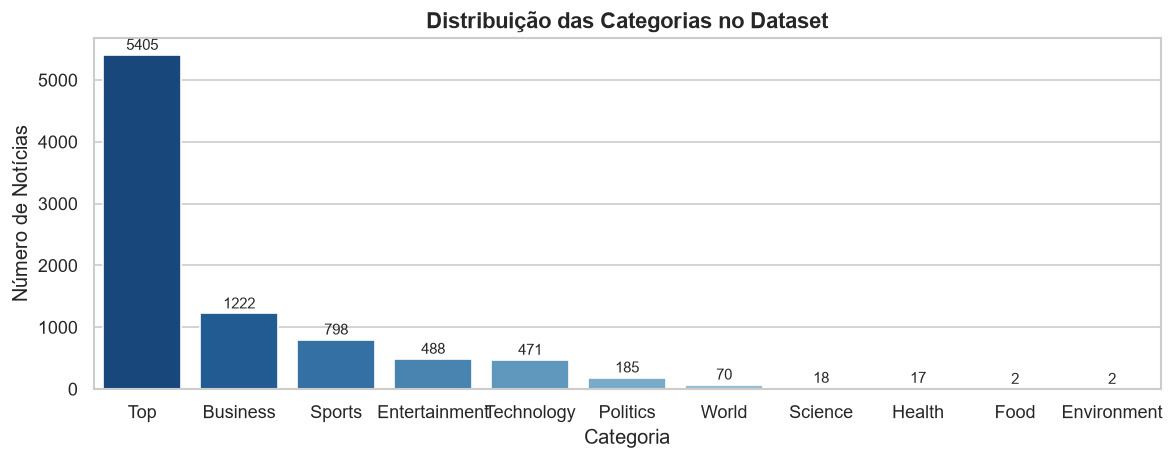

In [5]:
# ── Análise exploratória: distribuição das categorias ─────────────────────────
# O dataset apresenta forte desbalanceamento: a categoria "Top" concentra
# 62,3% dos registros, conforme descrito na metodologia do trabalho.

cat_counts = df['CATEGORY'].value_counts()
cat_pct    = (cat_counts / len(df) * 100).round(1)

print('Distribuição das categorias:')
print(pd.DataFrame({'Contagem': cat_counts, 'Percentual (%)': cat_pct}).to_string())

# Gráfico de barras
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=cat_counts.index, y=cat_counts.values, ax=ax, palette='Blues_r')
ax.set_title('Distribuição das Categorias no Dataset', fontsize=13, fontweight='bold')
ax.set_xlabel('Categoria')
ax.set_ylabel('Número de Notícias')
for bar, val in zip(ax.patches, cat_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            str(val), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('distribuicao_categorias.png', bbox_inches='tight')
plt.show()

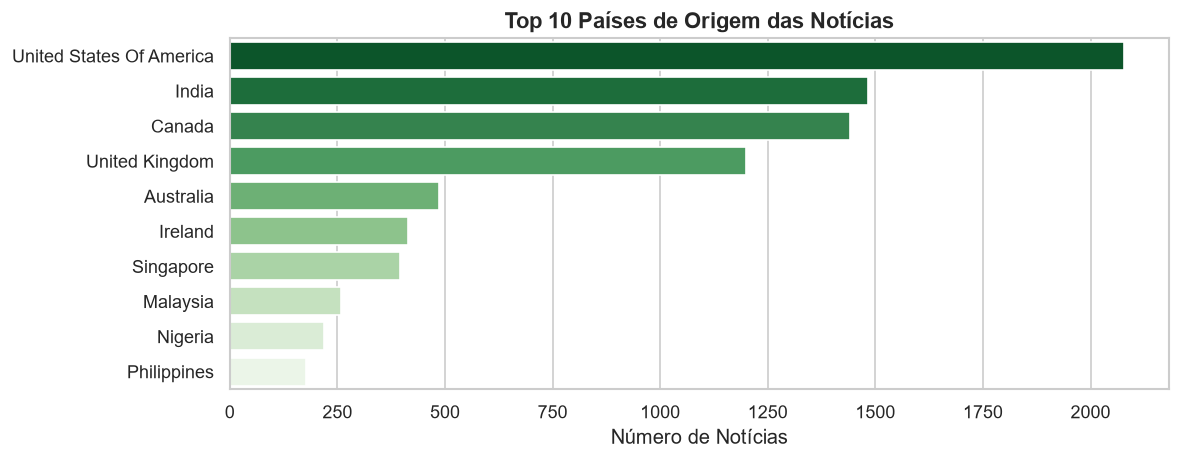

In [6]:
# ── Top 10 países de origem das notícias ──────────────────────────────────────
paises = df['COUNTRY'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=paises.values, y=paises.index, ax=ax, palette='Greens_r')
ax.set_title('Top 10 Países de Origem das Notícias', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de Notícias')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('distribuicao_paises.png', bbox_inches='tight')
plt.show()

In [7]:
# ── Verificação de valores ausentes ───────────────────────────────────────────
# A coluna DESCRIPTION apresenta 1.115 registros nulos que serão removidos,
# pois título + descrição formam a entrada textual dos modelos.

print('Valores ausentes por coluna:')
print(df.isnull().sum()[df.isnull().sum() > 0])

Valores ausentes por coluna:
AUTHOR         4331
PUBLISHER       123
DESCRIPTION    1115
IMAGE URL      4463
VIDEO URL      8662
dtype: int64


---
## 3. Etapa 2 — Pré-processamento

Seguindo a metodologia, os textos passam por um **pipeline de limpeza e normalização** com as seguintes etapas:

1. **Combinação** de `TITLE` + `DESCRIPTION` em um único campo de entrada
2. **Remoção de registros** com `DESCRIPTION` nula (~1.115 casos)
3. **Reagrupamento de categorias** — `Science`, `Health`, `Food` e `Environment` são unidas em `Other` por insuficiência de registros para treinamento
4. **Limpeza textual** — remoção de caracteres especiais, URLs e pontuação
5. **Normalização** — conversão para letras minúsculas
6. **Tokenização** — separação do texto em tokens (palavras)
7. **Remoção de stopwords** — eliminação de palavras sem valor discriminativo (ex.: *the*, *is*, *and*)
8. **Lematização** — redução das palavras à sua forma base (ex.: *running* → *run*)

In [8]:
# ── 3.1 Seleção de colunas e remoção de nulos ─────────────────────────────────
df_clean = df[['TITLE', 'DESCRIPTION', 'CATEGORY']].copy()

df_clean.dropna(subset=['DESCRIPTION'], inplace=True)
print(f'Registros após remoção de nulos: {len(df_clean)}')

# ── 3.2 Combinação de TITLE + DESCRIPTION ─────────────────────────────────────
# A concatenação enriquece o conteúdo semântico disponível para os modelos
# (Saavedra, 2023). Este campo é a base para ambos os pipelines.
df_clean['TEXT'] = df_clean['TITLE'].fillna('') + ' ' + df_clean['DESCRIPTION'].fillna('')

# ── 3.3 Reagrupamento das categorias com poucos registros ─────────────────────
OTHER_CATS = {'Science', 'Health', 'Food', 'Environment'}
df_clean['CATEGORY'] = df_clean['CATEGORY'].apply(
    lambda c: 'Other' if c in OTHER_CATS else c
)

print('\nDistribuição após reagrupamento:')
print(df_clean['CATEGORY'].value_counts())


Registros após remoção de nulos: 7563

Distribuição após reagrupamento:
CATEGORY
Top              4881
Business          923
Sports            590
Technology        451
Entertainment     441
Politics          174
World              70
Other              33
Name: count, dtype: int64


In [ ]:
# ── 3.4 Pipelines de pré-processamento diferenciados ─────────────────────────
#
# MOTIVAÇÃO: TF-IDF e BERT requerem pré-processamentos distintos.
#
# O TF-IDF opera sobre frequências de termos: stopwords inflam o vetor sem
# agregar valor discriminativo, e lematizar reduz esparsidade desnecessária.
# O pipeline completo (minúsculas, remoção de stopwords, lematização) é
# portanto adequado e recomendado para esta representação.
#
# O BERT, por outro lado, foi pré-treinado em texto natural — com pontuação,
# maiúsculas, stopwords e flexões intactas. Alimentá-lo com texto lematizado
# e sem stopwords degrada a qualidade dos embeddings, pois o modelo recebe
# uma distribuição de entrada diferente daquela vista durante o pré-treino.
# Para o BERT, aplica-se apenas limpeza superficial:
# remoção de URLs, tags HTML e caracteres de controle, preservando o restante.

lemmatizer = WordNetLemmatizer()
STOP_WORDS  = set(stopwords.words('english'))

# ── Pipeline para TF-IDF ──────────────────────────────────────────────────────
def preprocess_for_tfidf(text: str) -> str:
    """
    Pipeline completo para uso com TF-IDF:
      1. Remove URLs
      2. Remove caracteres não-alfabéticos
      3. Converte para minúsculas
      4. Tokeniza
      5. Remove stopwords e tokens curtos (< 2 chars)
      6. Lematiza
    """
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = text.lower().strip()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)


# ── Pipeline para BERT ────────────────────────────────────────────────────────
def preprocess_for_bert(text: str) -> str:
    """
    Limpeza superficial para uso com BERT:
      1. Remove URLs
      2. Remove tags HTML
      3. Remove caracteres de controle e sequências de espaços
      Mantém: pontuação, maiúsculas, stopwords e flexões verbais.
      O BertTokenizer cuida da tokenização internamente.
    """
    text = re.sub(r'http\S+|www\.\S+', '', text)   # remove URLs
    text = re.sub(r'<[^>]+>', '', text)             # remove tags HTML
    text = re.sub(r'[\x00-\x1f\x7f]', '', text)    # remove caracteres de controle
    text = re.sub(r' +', ' ', text).strip()         # normaliza espaços múltiplos
    return text


# ── Aplicação dos pipelines ───────────────────────────────────────────────────
print('Aplicando pipeline TF-IDF...')
t0 = time.time()
df_clean['TEXT_FOR_TFIDF'] = df_clean['TEXT'].apply(preprocess_for_tfidf)
print(f'  Concluído em {time.time()-t0:.1f}s')

print('Aplicando pipeline BERT...')
t0 = time.time()
df_clean['TEXT_FOR_BERT'] = df_clean['TEXT'].apply(preprocess_for_bert)
print(f'  Concluído em {time.time()-t0:.1f}s')

# Exemplo comparativo dos dois pipelines
idx = df_clean.index[0]
print('\n--- Comparação dos pipelines ---')
print('ORIGINAL  :', df_clean.loc[idx, 'TEXT'][:180])
print('TF-IDF    :', df_clean.loc[idx, 'TEXT_FOR_TFIDF'][:180])
print('BERT      :', df_clean.loc[idx, 'TEXT_FOR_BERT'][:180])


Aplicando pipeline TF-IDF...
  Concluído em 4.9s
Aplicando pipeline BERT...
  Concluído em 0.1s

--- Comparação dos pipelines ---
ORIGINAL  : "Independent Belarusian Filmmakers Condemn Russian Attack on Ukraine" A group of Belarusian filmmakers, many of whom fled their authoritarian homeland to Ukraine in 2020, have publ
TF-IDF    : independent belarusian filmmaker condemn russian attack ukraine group belarusian filmmaker many fled authoritarian homeland ukraine published open letter condemning russian invasio
BERT      : "Independent Belarusian Filmmakers Condemn Russian Attack on Ukraine" A group of Belarusian filmmakers, many of whom fled their authoritarian homeland to Ukraine in 2020, have publ


In [10]:
# ── 3.5 Codificação das classes e preparação dos vetores ─────────────────────
le = LabelEncoder()
df_clean['LABEL'] = le.fit_transform(df_clean['CATEGORY'])

label_map = dict(enumerate(le.classes_))
print('Mapeamento de rótulos:')
for k, v in label_map.items():
    print(f'  {k} → {v}')

# Exportamos os dois campos de texto e os rótulos
# O split será feito pelos índices para garantir conjuntos idênticos
X_tfidf = df_clean['TEXT_FOR_TFIDF'].values
X_bert  = df_clean['TEXT_FOR_BERT'].values
y       = df_clean['LABEL'].values

print(f'\nTotal de amostras: {len(y)}')


Mapeamento de rótulos:
  0 → Business
  1 → Entertainment
  2 → Other
  3 → Politics
  4 → Sports
  5 → Technology
  6 → Top
  7 → World

Total de amostras: 7563


In [ ]:
# ── 3.6 Divisão treino / teste ────────────────────────────────────────────────
# O split é realizado UMA ÚNICA VEZ sobre os índices numéricos, garantindo
# que treino e teste sejam compostos pelos mesmos registros nas duas
# representações — diferindo apenas no pré-processamento aplicado.
# stratify=y preserva a distribuição das classes em ambos os conjuntos.

indices = np.arange(len(y))
idx_train, idx_test, y_train, y_test = train_test_split(
    indices, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Aplica os mesmos índices aos dois campos de texto
X_train_clean = X_tfidf[idx_train]   # entrada do TF-IDF
X_test_clean  = X_tfidf[idx_test]

X_train_raw   = X_bert[idx_train]    # entrada do BERT
X_test_raw    = X_bert[idx_test]

print(f'Conjunto de treino : {len(idx_train)} amostras ({len(idx_train)/len(y)*100:.1f}%)')
print(f'Conjunto de teste  : {len(idx_test)} amostras ({len(idx_test)/len(y)*100:.1f}%)')
print('\nDistribuição de classes no treino:')
unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(unique, counts):
    print(f'  {label_map[u]:<15}: {c}')


Conjunto de treino : 5294 amostras (70.0%)
Conjunto de teste  : 2269 amostras (30.0%)

Distribuição de classes no treino:
  Business       : 646
  Entertainment  : 309
  Other          : 23
  Politics       : 122
  Sports         : 413
  Technology     : 316
  Top            : 3416
  World          : 49


---
## 4. Etapa 3 — Representação Textual

São adotadas duas abordagens distintas de representação numérica dos textos:

- **TF-IDF** (esparsa): pondera a frequência de cada termo pela sua raridade no corpus, gerando vetores de alta dimensionalidade
- **Embeddings BERT** (densa): extrai vetores de dimensão fixa (768) usando o modelo `bert-base-uncased` pré-treinado, capturando relações semânticas contextuais

In [12]:
# ── 4.1 Representação TF-IDF ──────────────────────────────────────────────────
# A matriz TF-IDF é ajustada (fit) exclusivamente sobre X_train_clean —
# o texto que passou pelo pipeline completo (minúsculas, sem stopwords,
# lematizado). Isso evita vazamento de informação do conjunto de teste
# e garante que o vocabulário reflita apenas os dados de treinamento.

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_clean)
X_test_tfidf  = tfidf.transform(X_test_clean)

print('Dimensões TF-IDF:')
print(f'  Treino : {X_train_tfidf.shape}  (amostras × features)')
print(f'  Teste  : {X_test_tfidf.shape}')
print(f'  Esparsidade: {100*(1 - X_train_tfidf.nnz / (X_train_tfidf.shape[0]*X_train_tfidf.shape[1])):.2f}%')


Dimensões TF-IDF:
  Treino : (5294, 50000)  (amostras × features)
  Teste  : (2269, 50000)
  Esparsidade: 99.90%


In [ ]:
# ── 4.2 Representação com Embeddings BERT ─────────────────────────────────────
# O BERT (Bidirectional Encoder Representations from Transformers) é um modelo
# de linguagem pré-treinado que produz vetores densos contextuais.
# Utilizamos o token [CLS] — vetor agregado da sequência inteira — como
# representação de cada notícia.
#
# NOTA: esta etapa é computacionalmente intensiva.
#       Se tiver GPU NVIDIA, instale o PyTorch com CUDA: https://pytorch.org/get-started/locally/

MODEL_NAME = 'bert-base-uncased'

print(f'Carregando tokenizador e modelo BERT: {MODEL_NAME}')
tokenizer_bert = BertTokenizer.from_pretrained(MODEL_NAME)
model_bert     = BertModel.from_pretrained(MODEL_NAME)

# Detectar e usar GPU se disponível
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_bert = model_bert.to(DEVICE)
model_bert.eval()  # modo de inferência (desativa dropout)

print(f'Modelo carregado. Dispositivo: {DEVICE}')

Carregando tokenizador e modelo BERT: bert-base-uncased


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Modelo carregado. Dispositivo: cpu


In [ ]:
# ── Função de extração de embeddings BERT ─────────────────────────────────────

def get_bert_embeddings(texts, batch_size=32, max_length=128):
    """
    Gera embeddings BERT para uma lista de textos minimamente processados
    (URLs e tags HTML removidos, mas com pontuação, maiúsculas e stopwords
    preservados — conforme esperado pelo modelo pré-treinado).

    O BertTokenizer realiza internamente a tokenização em subpalavras (WordPiece),
    o padding e o truncamento. O vetor [CLS] (posição 0 do último estado oculto)
    é usado como representação semântica global do documento.

    Parâmetros:
      texts      : lista de strings com limpeza superficial
      batch_size : amostras processadas por vez (ajuste conforme memória disponível)
      max_length : número máximo de tokens; textos maiores são truncados

    Retorna:
      np.ndarray de shape (n_amostras, 768)
    """
    all_embeddings = []
    n_batches = (len(texts) + batch_size - 1) // batch_size

    for i in range(0, len(texts), batch_size):
        batch = list(texts[i: i + batch_size])
        encoded = tokenizer_bert(
            batch,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors='pt'
        )
        encoded = {k: v.to(DEVICE) for k, v in encoded.items()}

        with torch.no_grad():
            outputs = model_bert(**encoded)

        cls_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
        all_embeddings.append(cls_embeddings)

        batch_num = i // batch_size + 1
        if batch_num % 10 == 0 or batch_num == n_batches:
            print(f'  Batch {batch_num}/{n_batches} processado...')

    return np.vstack(all_embeddings)


# Extração com texto natural (sem lematização ou remoção de stopwords)
print('Gerando embeddings BERT para o conjunto de TREINO...')
print('  (entrada: texto com limpeza superficial — pontuação e stopwords preservados)')
t0 = time.time()
X_train_bert = get_bert_embeddings(X_train_raw)
print(f'  Concluído em {time.time()-t0:.1f}s | Shape: {X_train_bert.shape}')

print('\nGerando embeddings BERT para o conjunto de TESTE...')
t0 = time.time()
X_test_bert = get_bert_embeddings(X_test_raw)
print(f'  Concluído em {time.time()-t0:.1f}s | Shape: {X_test_bert.shape}')


Gerando embeddings BERT para o conjunto de TREINO...
  (entrada: texto com limpeza superficial — pontuação e stopwords preservados)
  Batch 10/166 processado...
  Batch 20/166 processado...
  Batch 30/166 processado...
  Batch 40/166 processado...
  Batch 50/166 processado...
  Batch 60/166 processado...
  Batch 70/166 processado...
  Batch 80/166 processado...
  Batch 90/166 processado...
  Batch 100/166 processado...
  Batch 110/166 processado...
  Batch 120/166 processado...
  Batch 130/166 processado...
  Batch 140/166 processado...
  Batch 150/166 processado...
  Batch 160/166 processado...
  Batch 166/166 processado...
  Concluído em 382.2s | Shape: (5294, 768)

Gerando embeddings BERT para o conjunto de TESTE...
  Batch 10/71 processado...
  Batch 20/71 processado...
  Batch 30/71 processado...
  Batch 40/71 processado...
  Batch 50/71 processado...
  Batch 60/71 processado...
  Batch 70/71 processado...
  Batch 71/71 processado...
  Concluído em 158.8s | Shape: (2269, 768)


In [15]:
# ── Salvamento dos embeddings ─────────────────────────────────────────────────
# Salvar os embeddings evita recalculá-los em execuções futuras.
# Os arquivos .npy são salvos na mesma pasta do notebook.

np.save('X_train_bert.npy', X_train_bert)
np.save('X_test_bert.npy',  X_test_bert)
np.save('y_train.npy',      y_train)
np.save('y_test.npy',       y_test)

print('Embeddings salvos com sucesso.')
print('Para recarregá-los sem recalcular, use:')
print('  X_train_bert = np.load("X_train_bert.npy")')
print('  X_test_bert  = np.load("X_test_bert.npy")')


Embeddings salvos com sucesso.
Para recarregá-los sem recalcular, use:
  X_train_bert = np.load("X_train_bert.npy")
  X_test_bert  = np.load("X_test_bert.npy")


---
## 5. Etapa 4 — Modelagem

São treinadas **quatro combinações** de representação textual + algoritmo:

| # | Representação | Algoritmo |
|---|--------------|----------|
| 1 | TF-IDF       | SVM      |
| 2 | Embeddings BERT | SVM   |
| 3 | TF-IDF       | XGBoost  |
| 4 | Embeddings BERT | XGBoost |

Para cada combinação, os hiperparâmetros são selecionados via **Grid Search** com **5 rodadas de validação cruzada estratificada** sobre o conjunto de treino, mantendo o conjunto de teste completamente isolado até a avaliação final.

In [16]:
# ── Configuração da validação cruzada ─────────────────────────────────────────
# StratifiedKFold garante que cada fold preserve a proporção das classes,
# fundamental em datasets desbalanceados como este.

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Dicionário para armazenar os resultados de cada combinação
resultados = {}

def avaliar_modelo(nome, modelo_treinado, X_test_rep, y_test):
    """
    Calcula e armazena as métricas de avaliação para um modelo treinado.
    Retorna um dicionário com acurácia, precisão, recall e F1-score.
    """
    y_pred = modelo_treinado.predict(X_test_rep)
    metrics = {
        'Acurácia'  : accuracy_score(y_test, y_pred),
        'Precisão'  : precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall'    : recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1-score'  : f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'y_pred'    : y_pred
    }
    resultados[nome] = metrics
    print(f'\n  Acurácia : {metrics["Acurácia"]:.4f}')
    print(f'  Precisão : {metrics["Precisão"]:.4f}')
    print(f'  Recall   : {metrics["Recall"]:.4f}')
    print(f'  F1-score : {metrics["F1-score"]:.4f}')
    return metrics

### 5.1 SVM — Support Vector Machine

O SVM é avaliado com dois tipos de kernel (linear e RBF) e parâmetros `C` e `gamma` explorados via Grid Search. O parâmetro `C` controla o equilíbrio entre minimizar erros no treino e generalizar para novos dados; `gamma` define o alcance da influência de cada amostra de treino.

In [ ]:
# ── 5.1.1 SVM + TF-IDF ───────────────────────────────────────────────────────
# Grade de hiperparâmetros conforme a metodologia

print('=' * 60)
print('COMBINAÇÃO 1: SVM + TF-IDF')
print('=' * 60)

svm_param_grid = {
    'kernel': ['linear', 'rbf'],
    'C'     : [0.1, 1, 10, 100],
    'gamma' : [0.001, 0.01, 0.1, 1]
}

# Otimização da métrica F1-score weighted, pois é a métrica principal
# em datasets desbalanceados
svm_grid_tfidf = GridSearchCV(
    SVC(random_state=RANDOM_STATE),
    svm_param_grid,
    cv=CV,
    scoring='f1_weighted',
    n_jobs=-1,     # utiliza todos os núcleos disponíveis
    verbose=0
)

print('Executando Grid Search (SVM + TF-IDF)...')
t0 = time.time()
svm_grid_tfidf.fit(X_train_tfidf, y_train)
print(f'Concluído em {time.time()-t0:.1f}s')
print(f'Melhores hiperparâmetros: {svm_grid_tfidf.best_params_}')
print(f'Melhor F1-score (CV)    : {svm_grid_tfidf.best_score_:.4f}')

print('\nResultados no conjunto de TESTE:')
metricas_svm_tfidf = avaliar_modelo(
    'SVM + TF-IDF', svm_grid_tfidf.best_estimator_, X_test_tfidf, y_test
)

COMBINAÇÃO 1: SVM + TF-IDF
Executando Grid Search (SVM + TF-IDF)...
Concluído em 236.6s
Melhores hiperparâmetros: {'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}
Melhor F1-score (CV)    : 0.7358

Resultados no conjunto de TESTE:

  Acurácia : 0.7880
  Precisão : 0.7720
  Recall   : 0.7880
  F1-score : 0.7732


In [18]:
# ── 5.1.2 SVM + Embeddings BERT ──────────────────────────────────────────────
print('=' * 60)
print('COMBINAÇÃO 2: SVM + Embeddings BERT')
print('=' * 60)

svm_grid_bert = GridSearchCV(
    SVC(random_state=RANDOM_STATE),
    svm_param_grid,
    cv=CV,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=0
)

print('Executando Grid Search (SVM + BERT)...')
t0 = time.time()
svm_grid_bert.fit(X_train_bert, y_train)
print(f'Concluído em {time.time()-t0:.1f}s')
print(f'Melhores hiperparâmetros: {svm_grid_bert.best_params_}')
print(f'Melhor F1-score (CV)    : {svm_grid_bert.best_score_:.4f}')

print('\nResultados no conjunto de TESTE:')
metricas_svm_bert = avaliar_modelo(
    'SVM + BERT', svm_grid_bert.best_estimator_, X_test_bert, y_test
)

COMBINAÇÃO 2: SVM + Embeddings BERT
Executando Grid Search (SVM + BERT)...
Concluído em 921.2s
Melhores hiperparâmetros: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Melhor F1-score (CV)    : 0.7584

Resultados no conjunto de TESTE:

  Acurácia : 0.7929
  Precisão : 0.7764
  Recall   : 0.7929
  F1-score : 0.7803


### 5.2 XGBoost — Extreme Gradient Boosting

O XGBoost é um algoritmo ensemble que constrói sequencialmente um conjunto de árvores de decisão fracas, onde cada árvore subsequente corrige os erros das anteriores. Os hiperparâmetros buscados são: `n_estimators` (número de árvores), `max_depth` (profundidade máxima) e `learning_rate` (taxa de aprendizado).

In [ ]:
# ── 5.2.1 XGBoost + TF-IDF ───────────────────────────────────────────────────
print('=' * 60)
print('COMBINAÇÃO 3: XGBoost + TF-IDF')
print('=' * 60)

# Grade de hiperparâmetros conforme a metodologia
xgb_param_grid = {
    'n_estimators' : [100, 300, 500],
    'max_depth'    : [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3]
}

# use_label_encoder=False e eval_metric evitam avisos de depreciação
xgb_grid_tfidf = GridSearchCV(
    XGBClassifier(
        use_label_encoder=False,
        eval_metric='mlogloss',
        random_state=RANDOM_STATE,
        tree_method='hist'      # mais rápido, compatível com GPU e CPU
    ),
    xgb_param_grid,
    cv=CV,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=0
)

print('Executando Grid Search (XGBoost + TF-IDF)...')
t0 = time.time()
xgb_grid_tfidf.fit(X_train_tfidf, y_train)
print(f'Concluído em {time.time()-t0:.1f}s')
print(f'Melhores hiperparâmetros: {xgb_grid_tfidf.best_params_}')
print(f'Melhor F1-score (CV)    : {xgb_grid_tfidf.best_score_:.4f}')

print('\nResultados no conjunto de TESTE:')
metricas_xgb_tfidf = avaliar_modelo(
    'XGBoost + TF-IDF', xgb_grid_tfidf.best_estimator_, X_test_tfidf, y_test
)

COMBINAÇÃO 3: XGBoost + TF-IDF
Executando Grid Search (XGBoost + TF-IDF)...
Concluído em 3440.8s
Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300}
Melhor F1-score (CV)    : 0.7185

Resultados no conjunto de TESTE:

  Acurácia : 0.7585
  Precisão : 0.7416
  Recall   : 0.7585
  F1-score : 0.7344


In [20]:
# ── 5.2.2 XGBoost + Embeddings BERT ──────────────────────────────────────────
print('=' * 60)
print('COMBINAÇÃO 4: XGBoost + Embeddings BERT')
print('=' * 60)

xgb_grid_bert = GridSearchCV(
    XGBClassifier(
        use_label_encoder=False,
        eval_metric='mlogloss',
        random_state=RANDOM_STATE,
        tree_method='hist'
    ),
    xgb_param_grid,
    cv=CV,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=0
)

print('Executando Grid Search (XGBoost + BERT)...')
t0 = time.time()
xgb_grid_bert.fit(X_train_bert, y_train)
print(f'Concluído em {time.time()-t0:.1f}s')
print(f'Melhores hiperparâmetros: {xgb_grid_bert.best_params_}')
print(f'Melhor F1-score (CV)    : {xgb_grid_bert.best_score_:.4f}')

print('\nResultados no conjunto de TESTE:')
metricas_xgb_bert = avaliar_modelo(
    'XGBoost + BERT', xgb_grid_bert.best_estimator_, X_test_bert, y_test
)

COMBINAÇÃO 4: XGBoost + Embeddings BERT
Executando Grid Search (XGBoost + BERT)...
Concluído em 8269.5s
Melhores hiperparâmetros: {'learning_rate': 0.3, 'max_depth': 3, 'n_estimators': 500}
Melhor F1-score (CV)    : 0.7348

Resultados no conjunto de TESTE:

  Acurácia : 0.7779
  Precisão : 0.7611
  Recall   : 0.7779
  F1-score : 0.7553


---
## 6. Etapa 5 — Avaliação e Comparação dos Modelos

Os modelos são comparados pelas métricas: **acurácia**, **precisão**, **recall** e **F1-score** (métrica principal, pois equilibra precisão e recall em datasets desbalanceados). São gerados: tabela comparativa, gráfico de barras, matriz de confusão e relatório de classificação por classe para cada combinação.

In [21]:
# ── 6.1 Tabela comparativa de métricas ───────────────────────────────────────
MODELOS = ['SVM + TF-IDF', 'SVM + BERT', 'XGBoost + TF-IDF', 'XGBoost + BERT']
METRICAS_KEYS = ['Acurácia', 'Precisão', 'Recall', 'F1-score']

tabela = pd.DataFrame(
    {nome: {m: resultados[nome][m] for m in METRICAS_KEYS} for nome in MODELOS}
).T.round(4)

# Destaca o melhor valor em cada coluna
print('\n📊 Tabela Comparativa de Métricas (conjunto de teste)\n')
print(tabela.to_string())

# Identificar a melhor combinação pelo F1-score
melhor_modelo = tabela['F1-score'].idxmax()
melhor_f1     = tabela.loc[melhor_modelo, 'F1-score']
print(f'\n🏆 Melhor combinação pelo F1-score: {melhor_modelo} ({melhor_f1:.4f})')


📊 Tabela Comparativa de Métricas (conjunto de teste)

                  Acurácia  Precisão  Recall  F1-score
SVM + TF-IDF        0.7880    0.7720  0.7880    0.7732
SVM + BERT          0.7929    0.7764  0.7929    0.7803
XGBoost + TF-IDF    0.7585    0.7416  0.7585    0.7344
XGBoost + BERT      0.7779    0.7611  0.7779    0.7553

🏆 Melhor combinação pelo F1-score: SVM + BERT (0.7803)


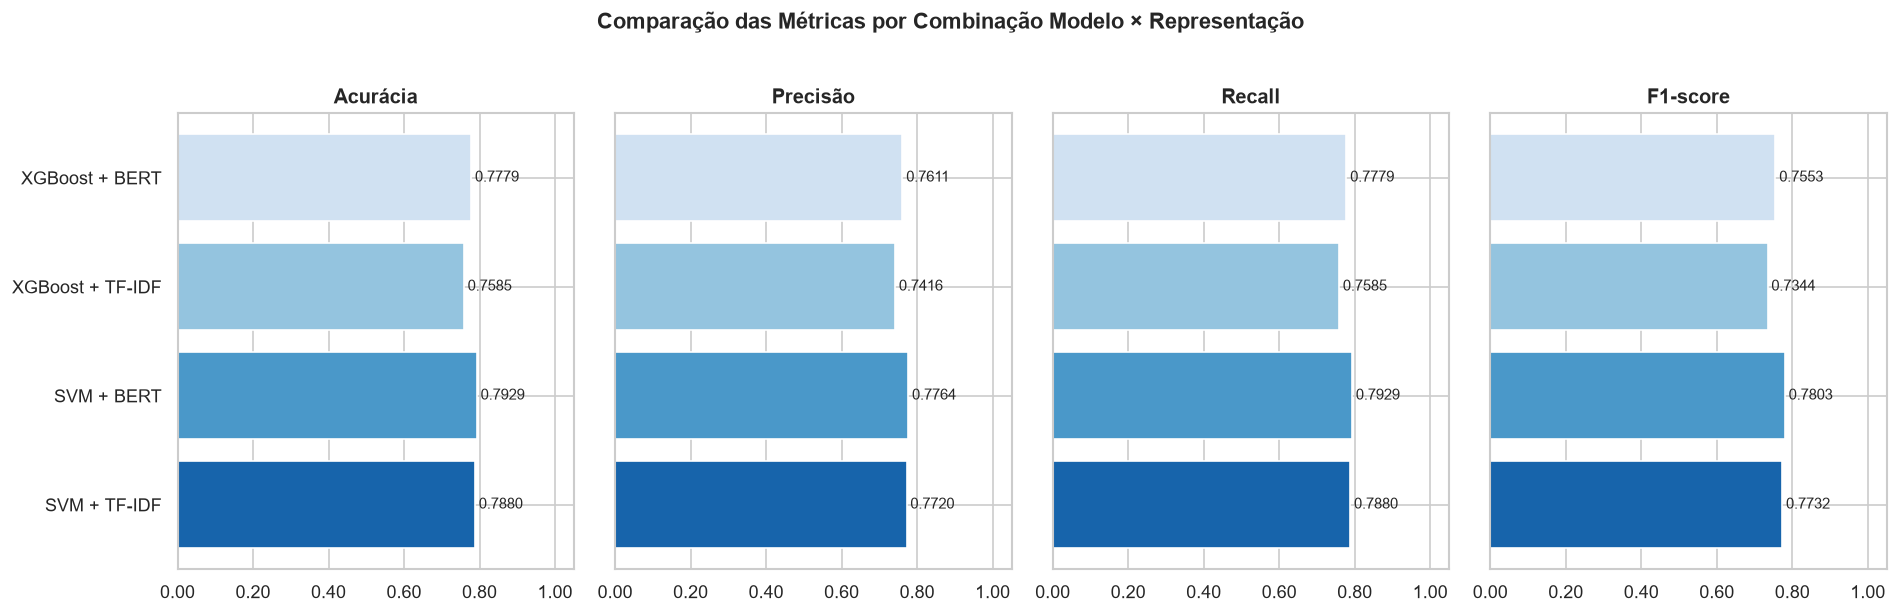

In [22]:
# ── 6.2 Gráfico comparativo das métricas ─────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
cores = sns.color_palette('Blues_r', n_colors=4)

for ax, metrica in zip(axes, METRICAS_KEYS):
    valores = tabela[metrica].values
    bars = ax.barh(MODELOS, valores, color=cores)
    ax.set_xlim(0, 1.05)
    ax.set_title(metrica, fontsize=12, fontweight='bold')
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))
    for bar, val in zip(bars, valores):
        ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=9)

fig.suptitle('Comparação das Métricas por Combinação Modelo × Representação',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('comparacao_metricas.png', bbox_inches='tight')
plt.show()

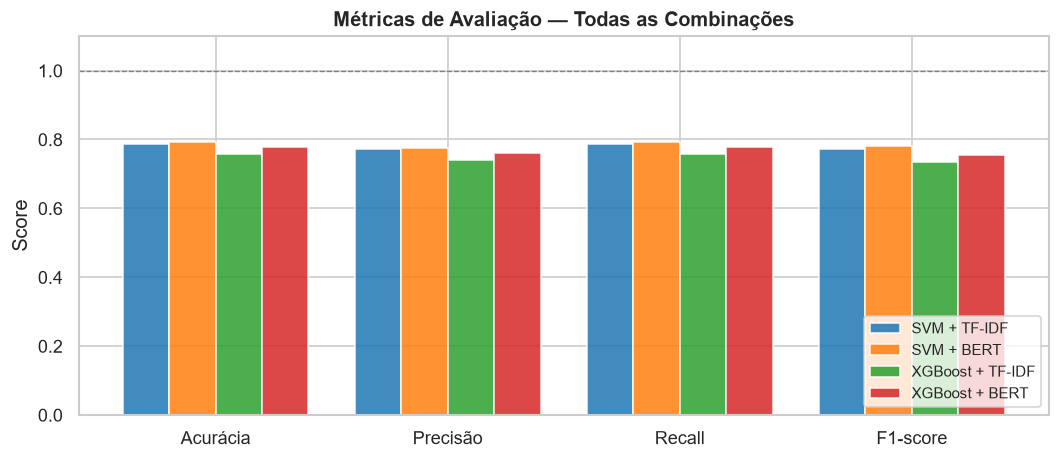

In [23]:
# ── 6.3 Gráfico de linhas — F1-score por combinação ──────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))

x = np.arange(len(METRICAS_KEYS))
largura = 0.2
cores_modelos = sns.color_palette('tab10', n_colors=len(MODELOS))

for i, (nome, cor) in enumerate(zip(MODELOS, cores_modelos)):
    vals = [tabela.loc[nome, m] for m in METRICAS_KEYS]
    ax.bar(x + i * largura, vals, width=largura, label=nome, color=cor, alpha=0.85)

ax.set_xticks(x + largura * 1.5)
ax.set_xticklabels(METRICAS_KEYS)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Métricas de Avaliação — Todas as Combinações', fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.axhline(y=1.0, color='gray', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.savefig('comparacao_barras_agrupadas.png', bbox_inches='tight')
plt.show()

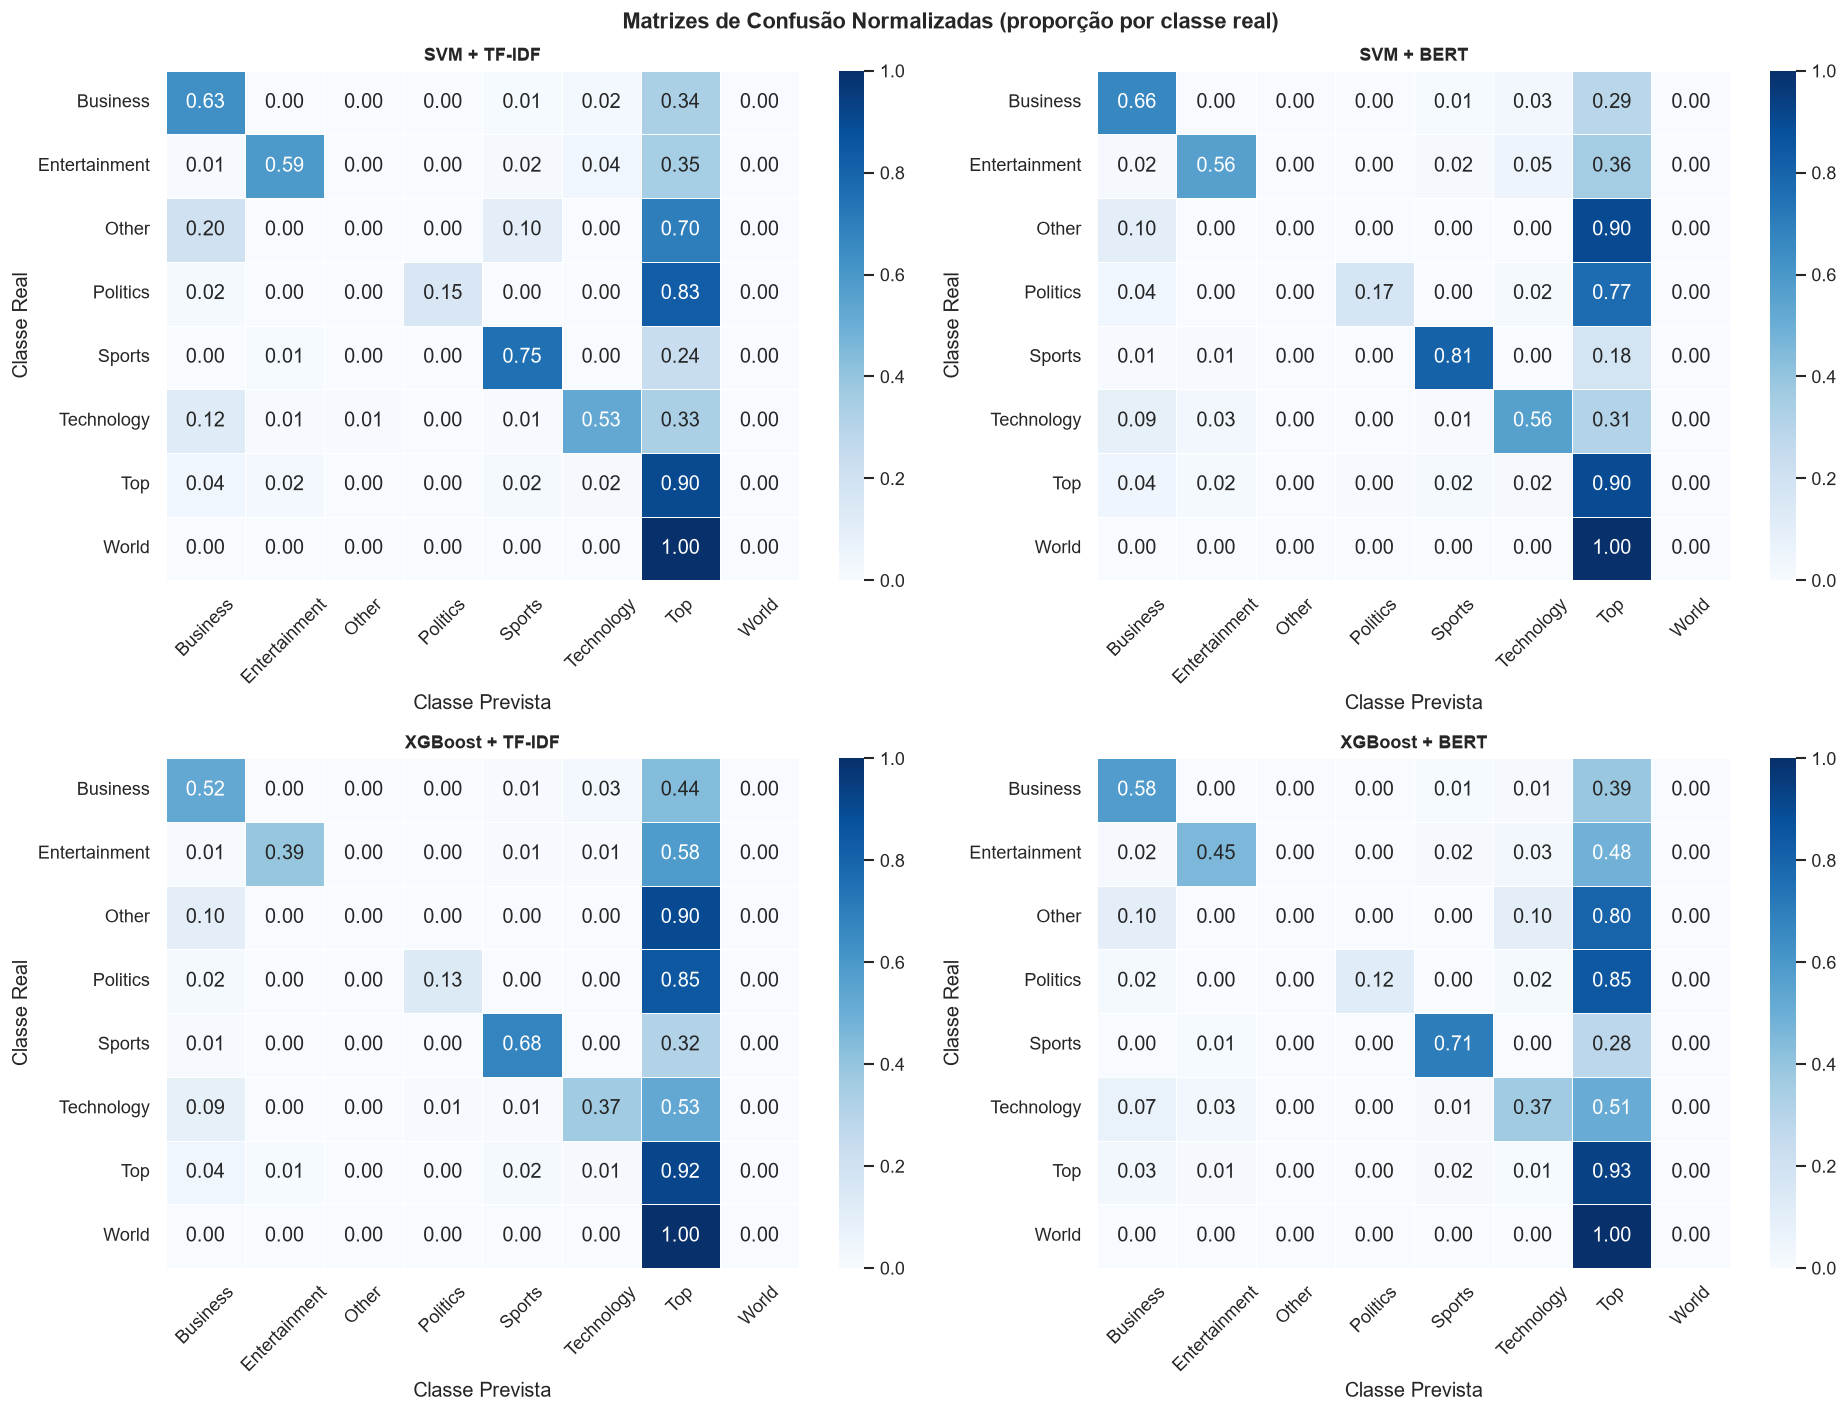

In [24]:
# ── 6.4 Matrizes de confusão ──────────────────────────────────────────────────
# A matriz de confusão mostra, para cada classe real (linhas),
# como as amostras foram distribuídas pelas classes previstas (colunas).
# A diagonal principal representa predições corretas.

CLASS_NAMES = le.classes_

PREDS = {
    'SVM + TF-IDF'     : resultados['SVM + TF-IDF']['y_pred'],
    'SVM + BERT'       : resultados['SVM + BERT']['y_pred'],
    'XGBoost + TF-IDF' : resultados['XGBoost + TF-IDF']['y_pred'],
    'XGBoost + BERT'   : resultados['XGBoost + BERT']['y_pred'],
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (nome, y_pred) in zip(axes.flatten(), PREDS.items()):
    cm = confusion_matrix(y_test, y_pred)
    # Normaliza pela quantidade real de cada classe (recall por linha)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(
        cm_norm, annot=True, fmt='.2f', cmap='Blues',
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        ax=ax, linewidths=0.5, vmin=0, vmax=1
    )
    ax.set_title(nome, fontsize=11, fontweight='bold')
    ax.set_xlabel('Classe Prevista')
    ax.set_ylabel('Classe Real')
    ax.tick_params(axis='x', rotation=45)

fig.suptitle('Matrizes de Confusão Normalizadas (proporção por classe real)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('matrizes_confusao.png', bbox_inches='tight')
plt.show()

In [25]:
# ── 6.5 Relatório de classificação por classe ─────────────────────────────────
# O relatório detalha precisão, recall e F1-score para cada categoria,
# permitindo identificar em quais classes cada modelo performa melhor ou pior.

for nome, y_pred in PREDS.items():
    print('=' * 70)
    print(f'RELATÓRIO DE CLASSIFICAÇÃO — {nome}')
    print('=' * 70)
    print(classification_report(
        y_test, y_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    ))

RELATÓRIO DE CLASSIFICAÇÃO — SVM + TF-IDF
               precision    recall  f1-score   support

     Business       0.70      0.63      0.66       277
Entertainment       0.70      0.59      0.64       132
        Other       0.00      0.00      0.00        10
     Politics       0.73      0.15      0.25        52
       Sports       0.79      0.75      0.77       177
   Technology       0.68      0.53      0.59       135
          Top       0.82      0.90      0.86      1465
        World       0.00      0.00      0.00        21

     accuracy                           0.79      2269
    macro avg       0.55      0.44      0.47      2269
 weighted avg       0.77      0.79      0.77      2269

RELATÓRIO DE CLASSIFICAÇÃO — SVM + BERT
               precision    recall  f1-score   support

     Business       0.69      0.66      0.68       277
Entertainment       0.70      0.56      0.62       132
        Other       0.00      0.00      0.00        10
     Politics       0.60      0.17

In [ ]:
i = list(CLASS_NAMES).index('Top')
for nome, y_pred in PREDS.items():
    cm = confusion_matrix(y_test, y_pred)
    erros = cm.sum() - cm.trace()
    para_top = cm[:, i].sum() - cm[i, i]
    f1m = f1_score(y_test, y_pred, average='macro', zero_division=0)
    print(f'{nome}: F1 macro={f1m:.4f} | erros={erros} | para Top={para_top} ({para_top/erros:.4f})')

In [26]:
# ── 6.6 Resumo final ──────────────────────────────────────────────────────────
print('=' * 70)
print('RESUMO FINAL — COMPARAÇÃO DAS COMBINAÇÕES')
print('=' * 70)
print(tabela[METRICAS_KEYS].sort_values('F1-score', ascending=False).to_string())

print('\n' + '=' * 70)
print(f'🏆 Melhor combinação : {melhor_modelo}')
print(f'   F1-score          : {tabela.loc[melhor_modelo, "F1-score"]:.4f}')
print(f'   Acurácia          : {tabela.loc[melhor_modelo, "Acurácia"]:.4f}')
print(f'   Precisão          : {tabela.loc[melhor_modelo, "Precisão"]:.4f}')
print(f'   Recall            : {tabela.loc[melhor_modelo, "Recall"]:.4f}')

# Comparação TF-IDF vs BERT por algoritmo
print('\n--- Impacto da representação textual ---')
for alg in ['SVM', 'XGBoost']:
    f1_tfidf = tabela.loc[f'{alg} + TF-IDF', 'F1-score']
    f1_bert  = tabela.loc[f'{alg} + BERT',   'F1-score']
    diff     = f1_bert - f1_tfidf
    print(f'{alg}: TF-IDF={f1_tfidf:.4f} | BERT={f1_bert:.4f} | Δ={diff:+.4f}')

RESUMO FINAL — COMPARAÇÃO DAS COMBINAÇÕES
                  Acurácia  Precisão  Recall  F1-score
SVM + BERT          0.7929    0.7764  0.7929    0.7803
SVM + TF-IDF        0.7880    0.7720  0.7880    0.7732
XGBoost + BERT      0.7779    0.7611  0.7779    0.7553
XGBoost + TF-IDF    0.7585    0.7416  0.7585    0.7344

🏆 Melhor combinação : SVM + BERT
   F1-score          : 0.7803
   Acurácia          : 0.7929
   Precisão          : 0.7764
   Recall            : 0.7929

--- Impacto da representação textual ---
SVM: TF-IDF=0.7732 | BERT=0.7803 | Δ=+0.0071
XGBoost: TF-IDF=0.7344 | BERT=0.7553 | Δ=+0.0209


---
## 7. Download dos Resultados

Exporta a tabela comparativa em CSV e faz o download de todos os gráficos gerados.

In [27]:
# ── Exportar tabela de resultados ─────────────────────────────────────────────
tabela.to_csv('resultados_comparativos.csv')
print('Arquivo resultados_comparativos.csv salvo na pasta do notebook.')

# Lista dos arquivos gerados durante a execução
import os
arquivos = [
    'resultados_comparativos.csv',
    'distribuicao_categorias.png',
    'distribuicao_paises.png',
    'comparacao_metricas.png',
    'comparacao_barras_agrupadas.png',
    'matrizes_confusao.png',
]
print('\nArquivos gerados:')
for arq in arquivos:
    status = '✅' if os.path.exists(arq) else '⚠️  não encontrado'
    print(f'  {status}  {arq}')


Arquivo resultados_comparativos.csv salvo na pasta do notebook.

Arquivos gerados:
  ✅  resultados_comparativos.csv
  ✅  distribuicao_categorias.png
  ✅  distribuicao_paises.png
  ✅  comparacao_metricas.png
  ✅  comparacao_barras_agrupadas.png
  ✅  matrizes_confusao.png


---
## Notas de Execução

**Tempo estimado de execução (ambiente local com GPU NVIDIA):**

| Etapa | CPU | GPU |
|---|---|---|
| Pré-processamento | ~5 min | ~5 min |
| Geração de embeddings BERT | ~60–90 min | ~10–15 min |
| Grid Search SVM + TF-IDF | ~20–40 min | ~20–40 min |
| Grid Search SVM + BERT | ~5–15 min | ~5–15 min |
| Grid Search XGBoost (×2) | ~15–30 min | ~10–20 min |

**Recomendações para execução local:**
- Salve os embeddings BERT após a extração (Seção 4.2) — em caso de reinicialização do kernel, recarregue com `np.load()` sem precisar recalcular
- Se tiver GPU NVIDIA, instale a versão correta do PyTorch com suporte CUDA: https://pytorch.org/get-started/locally/
- Para reduzir o tempo do Grid Search, substitua `GridSearchCV` por `RandomizedSearchCV` com `n_iter=20`
- Todos os arquivos gerados (gráficos, CSV, embeddings) são salvos na mesma pasta do notebook

**Referências:**
- DEVLIN et al. (2019) — BERT: Pre-training of Deep Bidirectional Transformers
- JOACHIMS (1998) — Text Categorization with SVMs
- SAAVEDRA (2023) — Comparação de métodos de AM para classificação de notícias
- OLIVEIRA (2025) — Análise de modelos de PLN para classificação de notícias da UFRN
- DRESSLER et al. (2023) — Classificação de Textos Escolares com AM
- GUSMÃO (2023) — Estudo Comparativo de Modelos de Classificação Textual
